<a href="https://colab.research.google.com/github/ProfeAgudelo/Modelaci-n_Estocastica/blob/main/Problema_1_Confiabilidad_de_sistema_multicomponente_con_C%C3%B3pula_Gaussiana.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Problema #1 : Confiabilidad de sistema Multicomponente con Cópula Gaussiana
**Presentado por**: Dayron Javier Agudelo\
**Fecha**: 19 de noviembre de 2026\
**Fundación Universitaria Los Libertadores**

En primer lugar, se realiza la configuración del entorno. Para ello se importan las librerias y se configuran los colores para la visualización

In [209]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, expon, uniform, spearmanr, t
from sklearn.preprocessing import StandardScaler

In [210]:
# =================================
# Colores para la visualización
# =================================

colores = {
    # Colores institucionales
    "principal": "#004F4A",
    "secundario": "#267C72",
    "terciario": "#76A99C",
    "claro": "#B8D0C7",
    # Colores complementarios
    "dorado": "#D69B48",
    "terracota": "#C76B5A",
    "azul": "#557A9C",
    "gris_azulado": "#647078",
    # Colores estructurales
    "fondo": "#F3F5F3",
    "blanco": "#FFFFFF",
    "texto": "#263238",
    "cuadricula": "#DDE3DF"
}

## Análisis exploratorio de los datos

In [211]:
data = pd.read_csv('/content/drive/MyDrive/Especialización en matemática aplicada/Modelación estocastica/Problema #1/datos_confiabilidad.csv')

In [212]:
data.head(10)

,ruido_sensor_1,ruido_sensor_2,ruido_sensor_3,ruido_sensor_4,ruido_sensor_5,tiempo_respuesta_1,tiempo_respuesta_2,tiempo_respuesta_3,tiempo_respuesta_4,tiempo_respuesta_5,error_medicion_1,error_medicion_2,error_medicion_3,error_medicion_4,error_medicion_5,temperatura,vibracion,voltaje,falla_sistema
0,2.502071,2.541307,0.914305,0.882714,2.103349,2.599360,0.490576,1.188897,3.227320,1.374766,-1.104881,-1.005745,1.831273,0.992859,-0.041964,24.820997,0.163567,12.125708,0
1,1.740494,-1.588195,-1.755260,-0.205856,0.088280,2.135727,0.021783,2.396443,0.679711,1.169203,-1.452959,-1.757090,1.784844,1.923084,0.924102,29.844016,0.176282,10.775090,0
2,1.580329,2.845928,-0.986591,-0.198471,1.851627,0.842062,1.356226,6.665887,1.121299,2.260488,-1.448042,-1.969767,-1.510877,-1.000308,1.767436,34.246277,0.092609,11.833183,0
3,1.292723,0.458160,0.074732,1.403383,0.048913,4.718138,2.109203,1.384531,0.310385,5.734003,0.361607,0.916166,0.478468,0.893282,-1.992262,35.036534,0.632798,12.037283,0
4,0.312343,1.727684,-1.532473,-2.202358,0.300033,0.884468,2.702262,1.476109,0.241005,1.986098,-0.822494,-0.767286,-0.451649,0.742006,-0.248693,25.073347,0.302833,12.476454,0
5,-1.324846,-1.319653,-2.696343,-1.971917,-0.512784,4.707241,0.019080,0.893337,0.399347,1.495624,1.754401,0.548259,-1.418567,-1.471140,-1.457992,25.793548,0.604008,10.612618,0
6,1.033859,1.534881,-1.328936,-0.776067,-0.849136,1.284524,0.397488,1.554306,0.590699,0.436956,0.975294,-1.053221,-0.063916,-1.585432,-0.506453,29.779153,0.312343,13.737953,0
7,-0.188461,1.094175,0.655323,0.244764,0.423441,1.253051,0.510254,0.579877,2.831564,2.822123,1.708343,1.940562,0.893294,-0.210149,0.748640,29.075720,0.160783,13.879226,0
8,1.453466,1.023714,1.380916,0.463683,0.535769,0.721793,1.536883,0.629985,0.792855,0.311735,1.909491,1.349964,-1.915809,0.911382,-0.347269,23.689560,0.193011,11.912125,0
9,-0.496132,0.519080,0.077448,-1.558158,-2.070263,5.212400,1.628158,1.165058,2.143611,0.337309,-0.112055,1.169597,-0.688055,0.239456,1.179445,20.488021,0.102333,13.048395,0


In [213]:
#Creación de los datasets por separado

ruido_cols = [f'ruido_sensor_{i}' for i in range(1, 6)]
data_ruido = data[ruido_cols]
tiempo_cols = [f'tiempo_respuesta_{i}' for i in range(1, 6)]
data_tiempo = data[tiempo_cols]
error_cols = [f'error_medicion_{i}' for i in range(1, 6)]
data_error = data[error_cols]

In [214]:
data_ruido.describe()

,ruido_sensor_1,ruido_sensor_2,ruido_sensor_3,ruido_sensor_4,ruido_sensor_5
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.002997,0.031786,0.000306,-0.002187,0.026622
std,1.487559,1.495397,1.481428,1.530948,1.520961
min,-4.529790,-5.329520,-4.428018,-5.585675,-5.713272
25%,-0.988309,-1.014986,-0.990422,-1.044955,-1.025644
50%,-0.007638,0.036654,0.033592,0.005561,0.056477
75%,1.053862,1.042676,0.997754,1.026299,1.041367
max,6.603212,4.918354,4.278804,4.860818,5.716971


In [215]:
#Normalización de los ruidos
scaler = StandardScaler()
data_ruido_norm = pd.DataFrame(
    scaler.fit_transform(data_ruido),   # data_ruido queda intacto
    columns=ruido_cols,
    index=data_ruido.index
)

In [216]:
data_ruido_norm.describe().drop('std')

,ruido_sensor_1,ruido_sensor_2,ruido_sensor_3,ruido_sensor_4,ruido_sensor_5
count,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03
mean,2.486900e-17,-7.105427e-18,-9.547918e-18,2.220446e-17,9.769963e-18
min,-3.047894e+00,-3.586102e+00,-2.989975e+00,-3.647992e+00,-3.774804e+00
25%,-6.665650e-01,-7.001708e-01,-6.689331e-01,-6.812963e-01,-6.920161e-01
50%,-7.151474e-03,3.256483e-03,2.247387e-02,5.061798e-03,1.963394e-02
75%,7.066124e-01,6.761703e-01,6.734697e-01,6.719649e-01,6.673400e-01
max,4.438054e+00,3.268557e+00,2.888813e+00,3.177261e+00,3.742221e+00


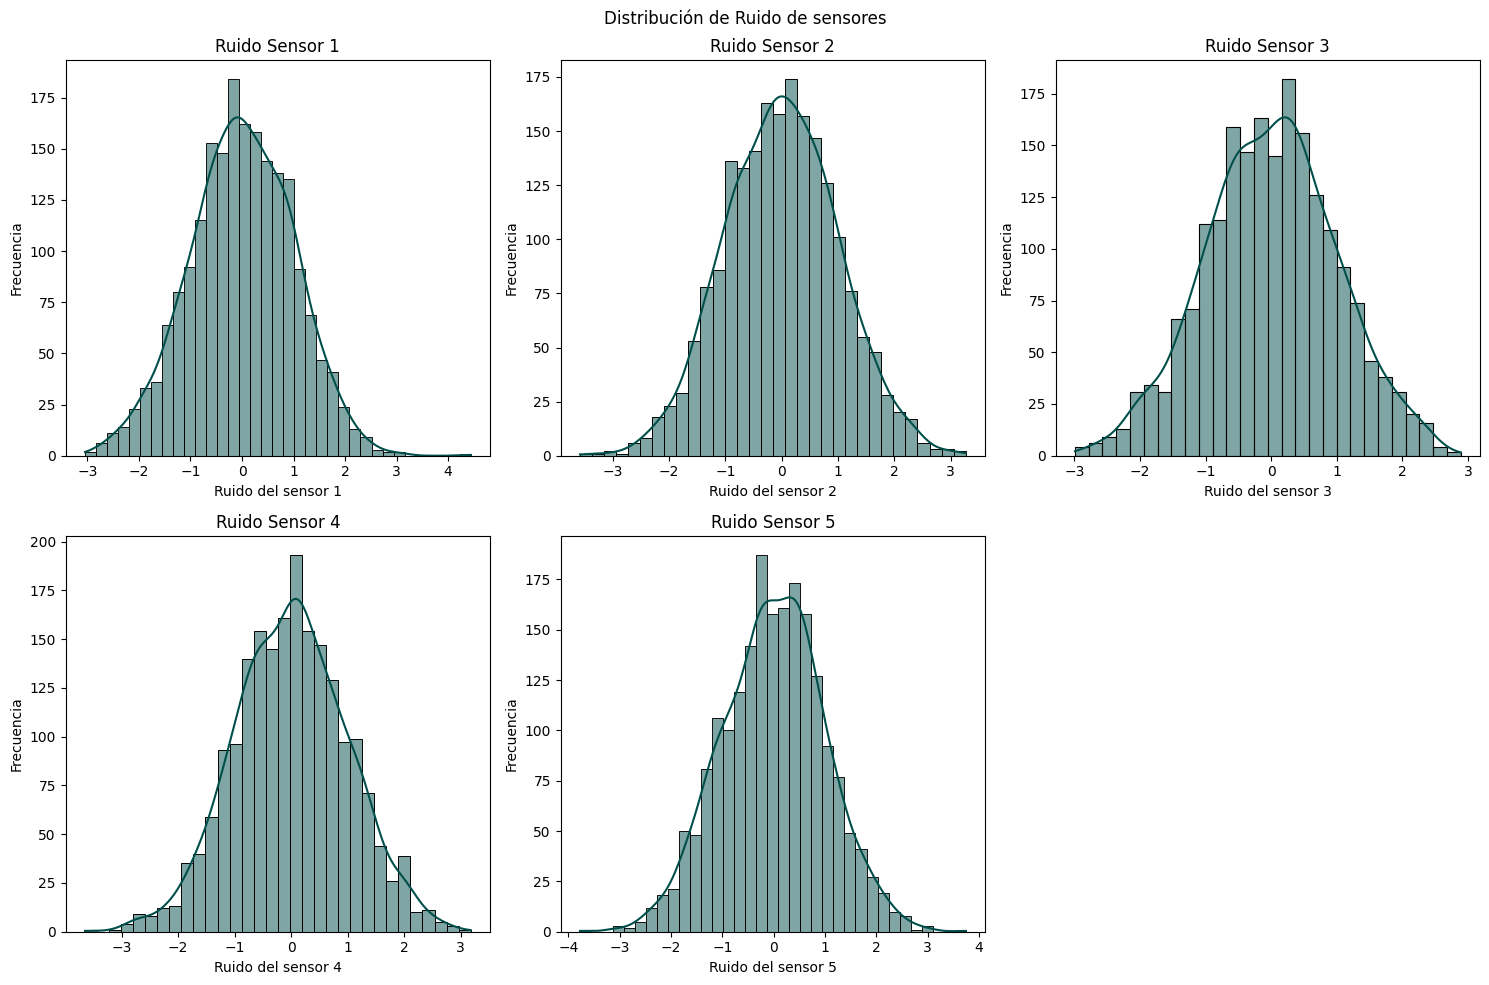

In [217]:
#Grafico de las distribuciones para el ruido
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
ax = ax.flatten()

for i in range(len(ruido_cols)):
    sns.histplot(data = data_ruido_norm[ruido_cols[i]], kde=True, color=colores['principal'], ax=ax[i])
    ax[i].set_xlabel(f'Ruido del sensor {i + 1}')
    ax[i].set_ylabel('Frecuencia')
    ax[i].set_title(f'Ruido Sensor {i + 1}')
    ax[5].axis('off')
fig.suptitle('Distribución de Ruido de sensores')
plt.tight_layout()
plt.show()

In [218]:
#Descripción del tiempo de respuesta
data_tiempo.describe().drop('std')

,tiempo_respuesta_1,tiempo_respuesta_2,tiempo_respuesta_3,tiempo_respuesta_4,tiempo_respuesta_5
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1.964010,1.979044,2.000795,2.024658,1.991060
min,0.001556,0.000686,0.003732,0.002632,0.000355
25%,0.558832,0.566522,0.594846,0.569670,0.565471
50%,1.375564,1.340652,1.371975,1.389121,1.400753
75%,2.733998,2.730240,2.727649,2.758188,2.813060
max,17.025002,14.596700,13.774662,16.338255,11.480702


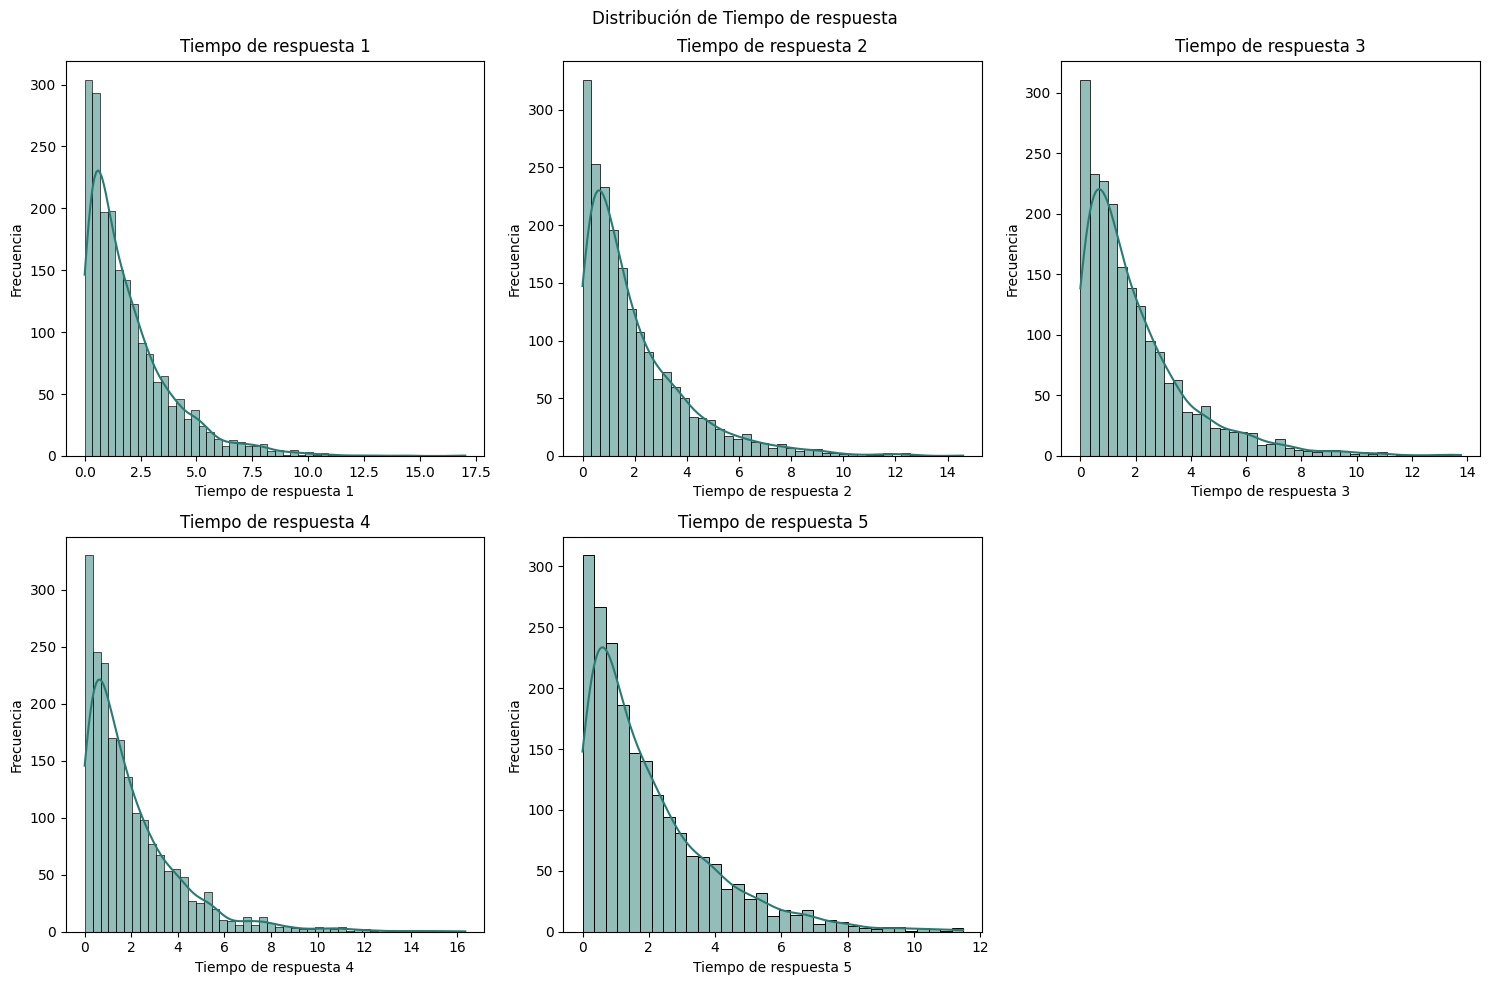

In [219]:
#Grafico de las distribuciones para el tiempo de respuesta
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
ax = ax.flatten()

for i in range(len(tiempo_cols)):
    sns.histplot(data = data_tiempo[tiempo_cols[i]], kde=True, color=colores['secundario'], ax=ax[i])
    ax[i].set_xlabel(f'Tiempo de respuesta {i + 1}')
    ax[i].set_ylabel('Frecuencia')
    ax[i].set_title(f'Tiempo de respuesta {i + 1}')
    ax[5].axis('off')
fig.suptitle('Distribución de Tiempo de respuesta')
plt.tight_layout()
plt.show()

In [220]:
#Descripción de los errores en la medición
data_error.describe().drop('std')

,error_medicion_1,error_medicion_2,error_medicion_3,error_medicion_4,error_medicion_5
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,-0.036497,0.000468,-0.013901,-0.016665,-0.000228
min,-1.999525,-1.999468,-1.999054,-1.998796,-1.998040
25%,-1.057028,-0.996687,-1.036451,-1.008212,-1.046338
50%,-0.021337,-0.014876,-0.008292,-0.017760,0.002460
75%,0.940386,1.036427,0.985601,0.943875,1.054371
max,1.997287,1.998315,1.995972,1.999124,1.996076


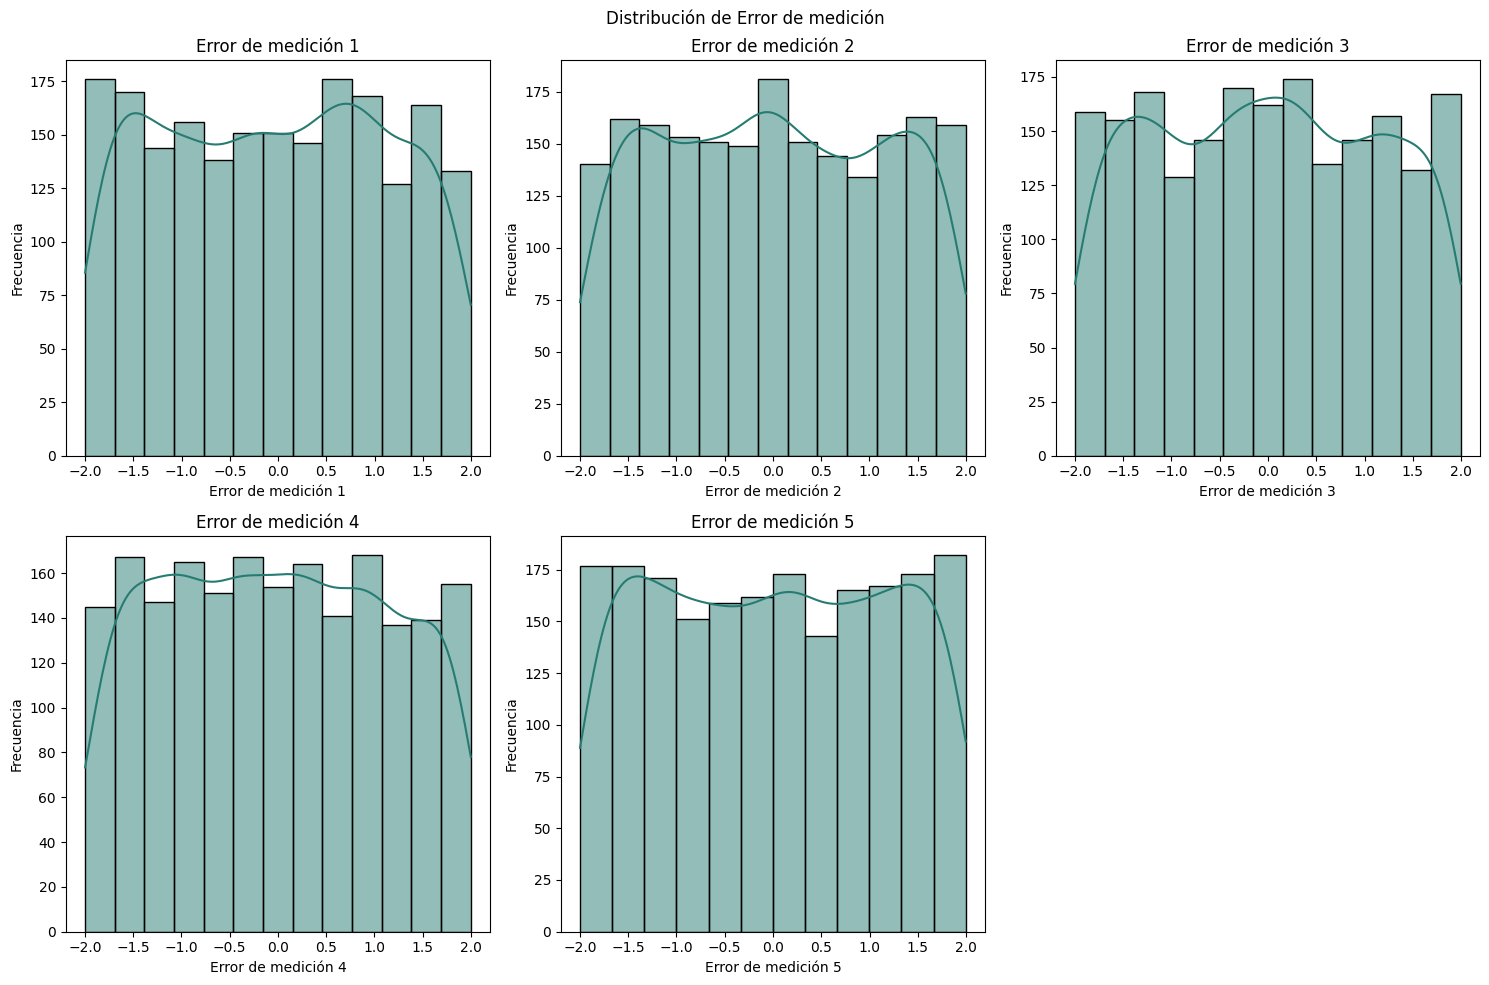

In [221]:
#Grafico de las distribuciones para el error
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
ax = ax.flatten()

for i in range(len(error_cols)):
    sns.histplot(data = data_error[error_cols[i]], kde=True, color=colores['secundario'], ax=ax[i])
    ax[i].set_xlabel(f'Error de medición {i + 1}')
    ax[i].set_ylabel('Frecuencia')
    ax[i].set_title(f'Error de medición {i + 1}')
    ax[5].axis('off')
fig.suptitle('Distribución de Error de medición')
plt.tight_layout()
plt.show()

In [222]:
data['vibracion'].describe().drop('std')

,vibracion
count,2000.000000
mean,0.509322
min,0.000175
25%,0.139497
50%,0.338888
75%,0.708172
max,5.876806


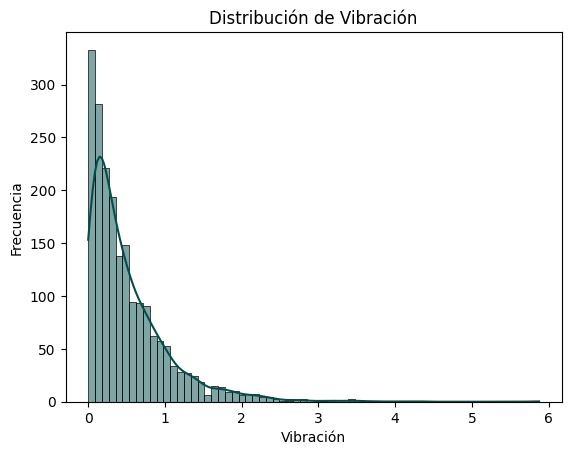

In [223]:
sns.histplot(data = data['vibracion'], kde=True, color=colores['principal'])
plt.xlabel('Vibración')
plt.ylabel('Frecuencia')
plt.title('Distribución de Vibración')
plt.show()

##Cálculo de los estimadores

In [224]:
for i in range(len(ruido_cols)):
    rms = np.sqrt((data_ruido[ruido_cols[i]]**2).mean())
    print(f'Valor de la desiavion para {ruido_cols[i]}: {round(rms, 5)}')

Valor de la desiavion para ruido_sensor_1: 1.48719
Valor de la desiavion para ruido_sensor_2: 1.49536
Valor de la desiavion para ruido_sensor_3: 1.48106
Valor de la desiavion para ruido_sensor_4: 1.53057
Valor de la desiavion para ruido_sensor_5: 1.52081


In [225]:
for i in range(len(tiempo_cols)):
    print(f'tiempo de respuesta {i + 1}')
    print(f'Valor de Lamda para el tiempo {i + 1}: {round(1/(data_tiempo[tiempo_cols[i]].mean()),5)}')

tiempo de respuesta 1
Valor de Lamda para el tiempo 1: 0.50916
tiempo de respuesta 2
Valor de Lamda para el tiempo 2: 0.50529
tiempo de respuesta 3
Valor de Lamda para el tiempo 3: 0.4998
tiempo de respuesta 4
Valor de Lamda para el tiempo 4: 0.49391
tiempo de respuesta 5
Valor de Lamda para el tiempo 5: 0.50225


In [226]:
for i in range(len(error_cols)):
    print(f'Error en la medición {i + 1}')
    print(f'Valores extremos para el error {i + 1}: Valor de a = {round(data_error[error_cols[i]].min(),5)} y valor de b = {round(data_error[error_cols[i]].max(),5)}')

Error en la medición 1
Valores extremos para el error 1: Valor de a = -1.99953 y valor de b = 1.99729
Error en la medición 2
Valores extremos para el error 2: Valor de a = -1.99947 y valor de b = 1.99832
Error en la medición 3
Valores extremos para el error 3: Valor de a = -1.99905 y valor de b = 1.99597
Error en la medición 4
Valores extremos para el error 4: Valor de a = -1.9988 y valor de b = 1.99912
Error en la medición 5
Valores extremos para el error 5: Valor de a = -1.99804 y valor de b = 1.99608


In [227]:
#Resumen de los estimadores
sigmas = np.sqrt((data_ruido[ruido_cols]**2).mean()).values
lambdas = 1.0 / data_tiempo[tiempo_cols].mean().values
a_hats = data_error[error_cols].min().values
b_hats = data_error[error_cols].max().values
mean_V = data['vibracion'].mean()

##Cálculo de la correlación de Spearman y prueba de hipotesis

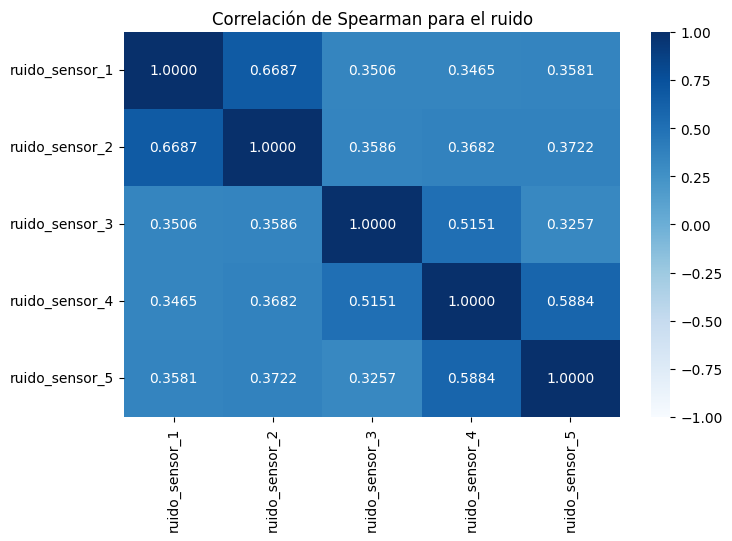

In [228]:
R = spearmanr(data_ruido)
data_R = pd.DataFrame(R[0])

#Grafico de correlación
plt.figure(figsize=(8,5))
cmap = sns.color_palette("Blues", as_cmap=True)
sns.heatmap(data_R, annot=True, cmap= cmap, fmt=".4f",vmin=-1, vmax=1,
            xticklabels=data_ruido.columns, yticklabels=data_ruido.columns)
plt.title('Correlación de Spearman para el ruido')
plt.show()

In [229]:
#Definición de la matriz de Cholesky
L_rho = np.linalg.cholesky(R[0])
L_rho

array([[1.        , 0.        , 0.        , 0.        , 0.        ],
       [0.66874267, 0.74349394, 0.        , 0.        , 0.        ],
       [0.35062266, 0.16700749, 0.92150543, 0.        , 0.        ],
       [0.34653712, 0.18356305, 0.39385684, 0.83132029, 0.        ],
       [0.35813351, 0.17850056, 0.18483076, 0.43149134, 0.78710276]])

In [230]:
#Prueba de la factorización de Cholesky
np.dot(L_rho,L_rho.transpose())

array([[1.        , 0.66874267, 0.35062266, 0.34653712, 0.35813351],
       [0.66874267, 1.        , 0.35864538, 0.36822217, 0.37221325],
       [0.35062266, 0.35864538, 1.        , 0.51510139, 0.3257032 ],
       [0.34653712, 0.36822217, 0.51510139, 1.        , 0.58837703],
       [0.35813351, 0.37221325, 0.3257032 , 0.58837703, 1.        ]])

In [231]:
n = len(data)
data_R_t = data_R.map(lambda x: round(x * np.sqrt((n - 2) / (1 - x**2)), 4) if abs(x) != 1 else np.nan)
data_R_t

,0,1,2,3,4
0,NaN,40.2049,16.7349,16.5131,17.1455
1,40.2049,NaN,17.1736,17.7030,17.9256
2,16.7349,17.1736,NaN,26.8624,15.3982
3,16.5131,17.7030,26.8624,NaN,32.5257
4,17.1455,17.9256,15.3982,32.5257,NaN


In [232]:
data_R_pVal = data_R_t.map(lambda x: 2*t.sf(abs(x), df=n-2))
data_R_pVal

,0,1,2,3,4
0,NaN,1.732578e-259,6.210138e-59,1.602869e-57,1.388652e-61
1,1.732578e-259,NaN,9.108904e-62,2.940837e-65,9.499411e-67
2,6.210138e-59,9.108904e-62,NaN,5.824863e-136,1.211426e-50
3,1.602869e-57,2.940837e-65,5.824863e-136,NaN,1.316461e-186
4,1.388652e-61,9.499411e-67,1.211426e-50,1.316461e-186,NaN


##Estimación empirica de la falla.

In [233]:
prop_data = (data['falla_sistema'].sum())/n
print(f'La proporción de fallas es: {round(prop_data, 5)}')

La proporción de fallas es: 0.0255


In [234]:
IC_prop_data_pos = prop_data + 1.96 * np.sqrt((prop_data * (1 - prop_data)) / n)
IC_prop_data_neg = prop_data - 1.96 * np.sqrt((prop_data * (1 - prop_data)) / n)
print('Con un 95% de confiabilidad es posible afirmar que la proporción se encuentra entre: ')
print(f'[{round(IC_prop_data_neg,5)} , {round(IC_prop_data_pos,5)}]')

Con un 95% de confiabilidad es posible afirmar que la proporción se encuentra entre: 
[0.01859 , 0.03241]


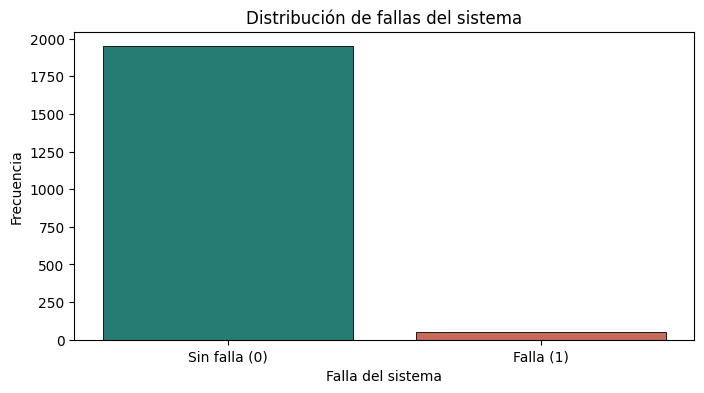

In [235]:
conteo = data['falla_sistema'].value_counts().sort_index()   # 0 = sin falla, 1 = falla

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(['Sin falla (0)', 'Falla (1)'], conteo.values,
                color=[colores['secundario'], colores['terracota']],
                edgecolor='black', linewidth=0.6)

plt.xlabel('Falla del sistema')
plt.ylabel('Frecuencia')
plt.title('Distribución de fallas del sistema')
plt.show()

##Calibración del parámetro theta $\theta$

In [236]:
#Variables proias del sistema
alpha = 0.25
beta_v = 0.10

def falla_componente(n, sigmas, lambdas, a_hats, b_hats, mean_V, K=5, L=L_rho, alpha = alpha, beta_v = beta_v):
  rng = np.random.default_rng(42)
  X = rng.standard_normal(size=(n, K))
  X_prime = (X @ L.T) * sigmas #Ruido con correlación
  T = rng.exponential(scale=1/lambdas, size=(n,K)) #Tiempo de respuesta
  E = rng.uniform(low=a_hats, high=b_hats, size=(n,K)) #Error Medido
  V = rng.exponential(scale=mean_V, size=(n,1)) #Vibración (Indagar al profe cual es el parámetro correcto de la exponencial)
  return np.abs(X_prime) + alpha*T + beta_v*V + np.abs(E)

def simulacion_falla_general(s):
  a = np.minimum(s[:,0],s[:,1])
  b = s[:,2]
  c = np.minimum(s[:,3],s[:,4])
  return np.maximum.reduce([a,b,c])

valores_falla = simulacion_falla_general(falla_componente(2000000, sigmas, lambdas, a_hats, b_hats, mean_V))

theta_calibrado = np.quantile(valores_falla, 1-prop_data)
print('El valor de theta calibrado es :', round(theta_calibrado, 5))


El valor de theta calibrado es : 5.47513


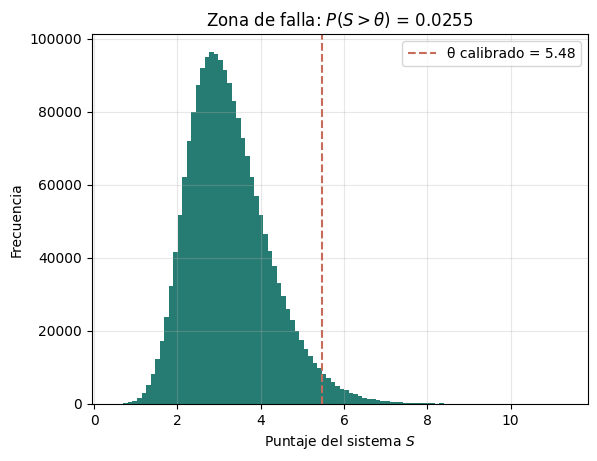

In [237]:
plt.hist(valores_falla,bins=100,color=colores['secundario'])
plt.axvline(theta_calibrado,ls='--', color=colores['terracota'], label=f'θ calibrado = {theta_calibrado:.2f}')
plt.xlabel('Puntaje del sistema $S$')
plt.ylabel('Frecuencia')
plt.title(f'Zona de falla: $P(S>\\theta)$ = {(valores_falla > theta_calibrado).mean():.4f}')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

##Modelo de Monte Carlo para fallas del sistema

In [238]:
def falla_sistema_sim(n, sigmas=sigmas, lambdas=lambdas, a_hats=a_hats, b_hats=b_hats, mean_V=mean_V, K=5, L=L_rho, alpha = alpha, beta_v = beta_v, thetha = theta_calibrado):
  rng = np.random.default_rng(42)
  X = rng.standard_normal(size=(n, K))
  X_prime = (X @ L.T) * sigmas #Ruido con correlación
  T = rng.exponential(scale=1/lambdas, size=(n,K)) #Tiempo de respuesta
  E = rng.uniform(low=a_hats, high=b_hats, size=(n,K)) #Error Medido
  V = rng.exponential(scale=mean_V, size=(n,1)) #Vibración (Indagar al profe cual es el parámetro correcto de la exponencial)

  #Función de falla
  fn = np.abs(X_prime) + alpha*T + beta_v*V + abs(E) > thetha

  #Falla en el sistema
  fn_a = fn[: , 0] & fn[:, 1]
  fn_b = fn[:, 2]
  fn_c = fn[:, 3] & fn[: , 4]

  return (fn_a | fn_b | fn_c).astype(float)

def estimadores_monte_carlo(data):
  prop_sis = data.mean()
  IC_prop_sis_pos = prop_sis + 1.96 * np.sqrt((prop_sis * (1 - prop_sis))/len(data))
  IC_prop_sis_neg = prop_sis - 1.96 * np.sqrt((prop_sis * (1 - prop_sis))/len(data))
  SE = np.sqrt((prop_sis * (1 - prop_sis))/len(data))
  return prop_sis, IC_prop_sis_pos, IC_prop_sis_neg, SE

In [239]:
ns = [100,500,1000,5000,10000,15000,25000,35000,45000,50000]
resultados = []

for i in range (len(ns)):
  data_monte_carlo = falla_sistema_sim(ns[i], sigmas, lambdas, a_hats, b_hats, mean_V)
  prop_sis, IC_prop_sis_pos, IC_prop_sis_neg, SE = estimadores_monte_carlo(data_monte_carlo)
  resultados.append({
        "n": ns[i],
        "prop_sis": prop_sis,
        "IC_neg": IC_prop_sis_neg,
        "IC_pos": IC_prop_sis_pos,
        "SE": SE
    })

resultados_df = pd.DataFrame(resultados)
resultados_df

,n,prop_sis,IC_neg,IC_pos,SE
0,100,0.010000,-0.009502,0.029502,0.009950
1,500,0.020000,0.007728,0.032272,0.006261
2,1000,0.025000,0.015323,0.034677,0.004937
3,5000,0.023200,0.019027,0.027373,0.002129
4,10000,0.025200,0.022128,0.028272,0.001567
5,15000,0.025467,0.022946,0.027988,0.001286
6,25000,0.023640,0.021757,0.025523,0.000961
7,35000,0.025086,0.023447,0.026724,0.000836
8,45000,0.025044,0.023601,0.026488,0.000737
9,50000,0.025440,0.024060,0.026820,0.000704


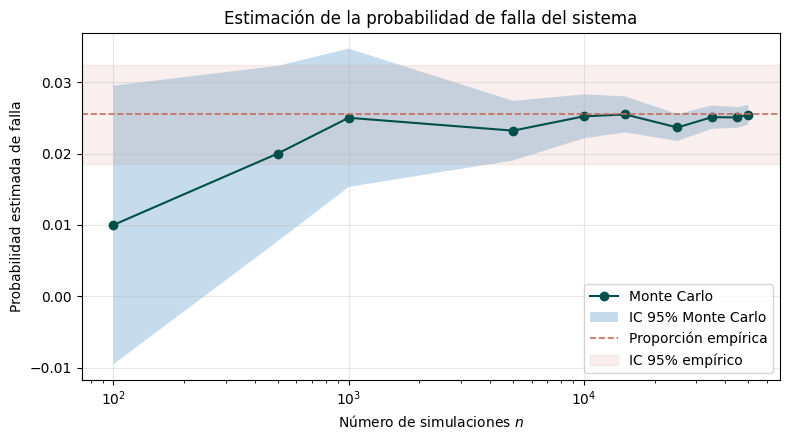

In [240]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(resultados_df["n"], resultados_df["prop_sis"], marker="o", label="Monte Carlo",color= colores['principal'])
ax.fill_between(resultados_df["n"], resultados_df["IC_neg"], resultados_df["IC_pos"],
                alpha=0.25, label="IC 95% Monte Carlo")

# Referencia empírica
ax.axhline(prop_data, color=colores['terracota'], ls="--", lw=1.2, label="Proporción empírica")
ax.axhspan(IC_prop_data_neg, IC_prop_data_pos, color=colores['terracota'], alpha=0.10,
           label="IC 95% empírico")

ax.set_xscale("log")
ax.set_xlabel("Número de simulaciones $n$")
ax.set_ylabel("Probabilidad estimada de falla")
ax.set_title("Estimación de la probabilidad de falla del sistema")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##Muestreo por importancia

In [241]:
from scipy.optimize import minimize

#Cálculo del punto de diseño
Sigma = np.outer(sigmas, sigmas) * R[0] #Da cuenta del valor Sigma del problema
Sigma_inv = np.linalg.inv(Sigma)

#Parametros: Valores esperados por cada distribución
E_T = data_tiempo.mean().values
E_abs_E = np.abs(data_error).mean().values
E_V = data['vibracion'].mean()

#Constantes
alpha, beta_V, theta = 0.25, 0.10, theta_calibrado

#Cálculo de función de ruidos
c = theta - alpha * E_T - beta_V * E_V - E_abs_E

print("--- Vector de umbrales de ruido ----")
print("Umbrales de ruido c_i por componente:", np.round(c, 3))


#Función objetivo: Minimizar (x^T Sigma^-1 x)
def objetivo(x):
    return float(x @ Sigma_inv @ x)

def grad_objetivo(x):
    return 2.0 * (Sigma_inv @ x)

# Definir los 3 caminos (restricciones de desigualdad >= 0 en SLSQP)
caminos = {
    "Camino A (F1 y F2)": [
        {'type': 'ineq', 'fun': lambda x: x[0] - c[0]},
        {'type': 'ineq', 'fun': lambda x: x[1] - c[1]},
    ],
    "Camino B (F3)": [
        {'type': 'ineq', 'fun': lambda x: x[2] - c[2]},
    ],
    "Camino C (F4 y F5)": [
        {'type': 'ineq', 'fun': lambda x: x[3] - c[3]},
        {'type': 'ineq', 'fun': lambda x: x[4] - c[4]},
    ]
}

resultados_caminos = {}
x0 = np.zeros(5)

print("--- Oprimización por cada uno de los caminos ---")
for nombre, restricciones in caminos.items():
    res = minimize(objetivo, x0, jac=grad_objetivo, method='SLSQP', constraints=restricciones)
    resultados_caminos[nombre] = (res.fun, res.x)
    print(f"{nombre:20s} -> x^T Sigma^-1 x = {res.fun:.4f} | x* = {np.round(res.x, 3)}")


--- Vector de umbrales de ruido ----
Umbrales de ruido c_i por componente: [3.928 3.936 3.93  3.931 3.902]
--- Oprimización por cada uno de los caminos ---
Camino A (F1 y F2)   -> x^T Sigma^-1 x = 8.3320 | x* = [3.928 3.936 1.66  1.728 1.755]
Camino B (F3)        -> x^T Sigma^-1 x = 7.0402 | x* = [1.383 1.422 3.93  2.092 1.314]
Camino C (F4 y F5)   -> x^T Sigma^-1 x = 8.2970 | x* = [1.694 1.789 2.013 3.931 3.902]


In [254]:
#Muestreo por importancia
mu_shift = np.array([1.383, 1.422, 3.93, 2.092, 1.314])
mu_shift = 0.4*mu_shift

def muestreo_importancia(
    n, mu_shift=mu_shift, Sigma=Sigma, sigmas=sigmas, lambdas=lambdas,
    a_hats=a_hats, b_hats=b_hats, mean_V=mean_V, K=5, L=L_rho,
    alpha=alpha, beta_v=beta_v, thetha=theta_calibrado
):
    rng = np.random.default_rng(42)
    X = rng.standard_normal(size=(n, K))
    signos = rng.choice([-1.0, 1.0], size=(n, 1))
    X_prime = (X @ L.T) * sigmas + signos*mu_shift  # Ruido correlacionado y desplazado
    T = rng.exponential(scale=1/lambdas, size=(n, K))
    E = rng.uniform(low=a_hats, high=b_hats, size=(n, K))
    V = rng.exponential(scale=mean_V, size=(n, 1))

    # Función de falla
    fn = np.abs(X_prime) + alpha * T + beta_v * V + np.abs(E) > thetha

    # Falla en el sistema
    fn_a = fn[:, 0] & fn[:, 1]
    fn_b = fn[:, 2]
    fn_c = fn[:, 3] & fn[:, 4]
    falla = (fn_a | fn_b | fn_c).astype(float)

    # Cálculo de los pesos usando X_prime (Teniendo en cuenta el desplazamiento positivo y negativo)
    Sigma_inv_mu = np.linalg.solve(Sigma, mu_shift)
    a_vec = X_prime @ Sigma_inv_mu
    b_val = 0.5 * (mu_shift @ Sigma_inv_mu)
    log_cosh = np.logaddexp(a_vec, -a_vec) - np.log(2.0) #Ayuda con la estabilidad númerica.
    w = np.exp(b_val - log_cosh)

    # Estimador, error estándar real de IS e Intervalo de Confianza
    Y = falla * w
    prop_sis_IS = np.mean(Y)
    se_IS = np.std(Y, ddof=1) / np.sqrt(n)
    IC_prop_sis_IS_pos = prop_sis_IS + 1.96 * se_IS
    IC_prop_sis_IS_neg = prop_sis_IS - 1.96 * se_IS
    ESS = (np.sum(w) ** 2) / np.sum(w ** 2)

    return prop_sis_IS, IC_prop_sis_IS_pos, IC_prop_sis_IS_neg, ESS, se_IS

In [255]:
p_hat = []
se = []
IC_pos = []
IC_neg = []
ess_list = []

for n_actual in ns:
    prop_sis_IS, ic_p, ic_n, ess_val, se_IS = muestreo_importancia(n_actual)
    p_hat.append(prop_sis_IS)
    se.append(se_IS)
    IC_pos.append(ic_p)
    IC_neg.append(ic_n)
    ess_list.append(ess_val)

resultados_IS = pd.DataFrame({
    "n": ns,
    "prop_sis_IS": p_hat,
    "IC_prop_sis_IS_neg": IC_neg,
    "IC_prop_sis_IS_pos": IC_pos,
    "se_IS": se,
    "ESS": ess_list,
    "ESS_%": [100 * e / n_actual for e, n_actual in zip(ess_list, ns)]
})

resultados_IS

,n,prop_sis_IS,IC_prop_sis_IS_neg,IC_prop_sis_IS_pos,se_IS,ESS,ESS_%
0,100,0.028147,0.001412,0.054883,0.013641,83.916004,83.916004
1,500,0.024025,0.016081,0.031968,0.004053,396.503383,79.300677
2,1000,0.022607,0.015826,0.029389,0.003460,809.048646,80.904865
3,5000,0.022674,0.019769,0.025578,0.001482,3974.545881,79.490918
4,10000,0.026966,0.024688,0.029243,0.001162,7907.434225,79.074342
5,15000,0.025465,0.023741,0.027189,0.000880,11815.837516,78.772250
6,25000,0.025296,0.023900,0.026693,0.000713,19709.325153,78.837301
7,35000,0.025839,0.024679,0.026999,0.000592,27525.005748,78.642874
8,45000,0.025794,0.024750,0.026838,0.000533,35439.469611,78.754377
9,50000,0.025709,0.024724,0.026693,0.000502,39424.736636,78.849473


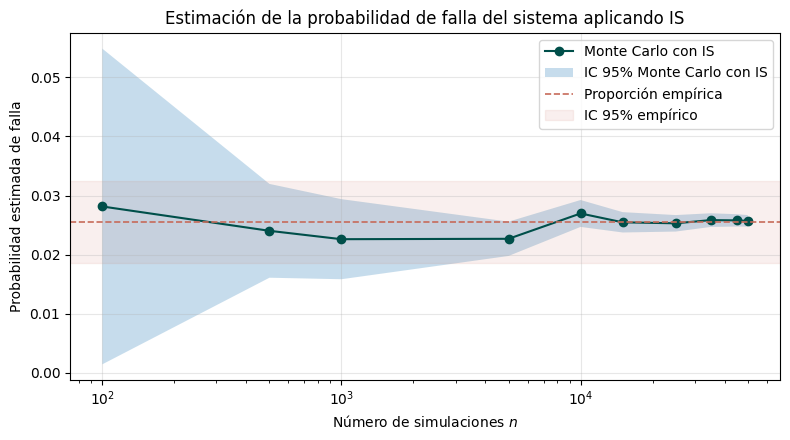

In [257]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(resultados_IS["n"], resultados_IS["prop_sis_IS"], marker="o", label="Monte Carlo con IS",color= colores['principal'])
ax.fill_between(resultados_IS["n"], resultados_IS["IC_prop_sis_IS_neg"], resultados_IS["IC_prop_sis_IS_pos"],
                alpha=0.25, label="IC 95% Monte Carlo con IS")

# Referencia empírica
ax.axhline(prop_data, color=colores['terracota'], ls="--", lw=1.2, label="Proporción empírica")
ax.axhspan(IC_prop_data_neg, IC_prop_data_pos, color=colores['terracota'], alpha=0.10,
           label="IC 95% empírico")

ax.set_xscale("log")
ax.set_xlabel("Número de simulaciones $n$")
ax.set_ylabel("Probabilidad estimada de falla")
ax.set_title("Estimación de la probabilidad de falla del sistema aplicando IS")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [245]:
# 1. Generamos una sola muestra base de aleatorios (Common Random Numbers)
#    para que la evaluación de p_sis sea determinista y sin ruido extra
M_interno = 2000
rng_base = np.random.default_rng(42)

Z_base = rng_base.standard_normal((M_interno, 5)) @ L_rho.T
Exp_T_base = rng_base.exponential(scale=1.0, size=(M_interno, 5))   # Exp(1), luego se divide por lambda
E_base = rng_base.uniform(low=a_hats, high=b_hats, size=(M_interno, 5))
V_base = rng_base.exponential(scale=mean_V, size=(M_interno, 1))

def evaluar_modelo(matriz_factores):
    """
    Recibe una matriz (N, 3) con factores [f_sigma, f_lambda, f_theta]
    y devuelve un vector de tamaño N con la probabilidad de falla del sistema.
    """
    N_eval = matriz_factores.shape[0]
    resultados = np.empty(N_eval)

    for i in range(N_eval):
        f_sig, f_lam, f_th = matriz_factores[i]

        X_sim = Z_base * (sigmas * f_sig)
        T_sim = Exp_T_base / (lambdas * f_lam)
        th_sim = theta_calibrado * f_th

        fn = np.abs(X_sim) + alpha * T_sim + beta_v * V_base + np.abs(E_base) > th_sim
        falla = (fn[:, 0] & fn[:, 1]) | fn[:, 2] | (fn[:, 3] & fn[:, 4])
        resultados[i] = np.mean(falla)

    return resultados

# 2. Construir matrices A y B de tamaño (N, 3) variando cada parámetro ±20%
N_sobol = 1000
rng_sobol = np.random.default_rng(123)
A = rng_sobol.uniform(0.8, 1.2, size=(N_sobol, 3))
B = rng_sobol.uniform(0.8, 1.2, size=(N_sobol, 3))

# Evaluar el modelo en A y B
Y_A = evaluar_modelo(A)
Y_B = evaluar_modelo(B)

# Varianza total estimada usando las 2N evaluaciones base
var_total = np.var(np.concatenate([Y_A, Y_B]), ddof=1)

# 3. Estimador de Jansen para cada parámetro k en {sigma, lambda, theta}
nombres = ["sigma (ruido)", "lambda (tiempo resp.)", "theta (umbral)"]
indices_S1 = []

for k in range(3):
    # C_k comparte SOLO la columna k con A; las otras dos columnas vienen de B
    C_k = B.copy()
    C_k[:, k] = A[:, k]
    Y_Ck = evaluar_modelo(C_k)

    # Fórmula de Jansen (ecuación 2.6)
    numerador = np.mean((Y_A - Y_Ck) ** 2) / 2.0
    S1_k = 1.0 - (numerador / var_total)
    indices_S1.append(S1_k)

tabla_sobol = pd.DataFrame({
    "Parámetro": nombres,
    "S1 (Primer orden)": indices_S1,
    "Contribución (%)": [100 * s for s in indices_S1]
}).sort_values("S1 (Primer orden)", ascending=False)

print(f"Suma de S1: {sum(indices_S1):.4f} (si es < 1, la diferencia son interacciones entre parámetros)")
tabla_sobol

Suma de S1: 0.9505 (si es < 1, la diferencia son interacciones entre parámetros)


,Parámetro,S1 (Primer orden),Contribución (%)
2,theta (umbral),0.715569,71.556945
0,sigma (ruido),0.221360,22.136025
1,lambda (tiempo resp.),0.013592,1.359211
